# 6. Model Training — LightGBM
Baseline đầu tiên trong chuỗi so sánh model. Train + đánh giá qua group k-fold (5 fold, ranh giới đã chốt ở bước preprocessing), lưu model từng fold vào `model/checkpoints/lightgbm/`, và ghi kết quả vào bảng so sánh chung `model/results/cv_results.csv` để đối chiếu với các model train sau (XGBoost, Random Forest, Logistic Regression).

## 6.0 Import & cấu hình

In [2]:
import pandas as pd
import numpy as np
import json
import os
import time
import lightgbm as lgb
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import seaborn as sns

CHECKPOINT_DIR = "../data/checkpoints"
MODEL_DIR = "checkpoints/lightgbm"  
RESULTS_PATH = "results/cv_results.csv"
MODEL_NAME = "lightgbm"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(os.path.dirname(RESULTS_PATH), exist_ok=True)

RISK_ORDER = {"Normal": 0, "Watch": 1, "Alert": 2, "Critical": 3}
CLASS_NAMES = ["Normal", "Watch", "Alert", "Critical"]
RANDOM_STATE = 42

## 6.1 Load checkpoint từ bước preprocessing

In [3]:
dev_df = pd.read_parquet(f"{CHECKPOINT_DIR}/dev_df.parquet")
test_df = pd.read_parquet(f"{CHECKPOINT_DIR}/test_df.parquet")
manifest = json.load(open(f"{CHECKPOINT_DIR}/split_manifest.json"))

FEATURE_COLS = manifest["feature_cols"]
TARGET_COL = manifest["target_col"]
N_FOLDS = manifest["n_folds"]

print(f"dev_df: {dev_df.shape}, test_df: {test_df.shape}, n_folds={N_FOLDS}")

dev_df: (69409, 48), test_df: (13094, 47), n_folds=40


## 6.2 Encode feature & chuẩn bị X/y

In [4]:
def encode_features(d):
    d = d.copy()
    d["risk_level"] = d["risk_level"].map(RISK_ORDER).astype(int)
    return d

dev_enc = encode_features(dev_df)
X_dev = dev_enc[FEATURE_COLS]
y_dev = dev_enc[TARGET_COL].map(RISK_ORDER).astype(int)
fold_id = dev_enc["fold_id"].astype(int)

## 6.3 Hàm ghi kết quả vào bảng so sánh chung
Append từng dòng `(model_name, fold_id, metric...)` vào `results/cv_results.csv` — dùng chung cho mọi notebook model sau này, để không phải tự gom tay nhiều file kết quả.

In [5]:
def log_fold_result(results_path, model_name, fold_id, n_val, train_seconds, y_true, y_pred):
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=[0, 1, 2, 3], zero_division=0
    )
    row = {
        "model_name": model_name,
        "fold_id": fold_id,
        "n_val": n_val,
        "train_seconds": round(train_seconds, 2),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
    }
    for i, cls in enumerate(CLASS_NAMES):
        row[f"precision_{cls}"] = precision[i]
        row[f"recall_{cls}"] = recall[i]
        row[f"f1_{cls}"] = f1[i]
        row[f"support_{cls}"] = support[i]

    df_row = pd.DataFrame([row])
    header = not os.path.exists(results_path)
    df_row.to_csv(results_path, mode="a", header=header, index=False)
    return row

## 6.4 Vòng lặp group k-fold: train + lưu model + ghi kết quả

In [6]:
LGB_PARAMS = dict(
    objective="multiclass", num_class=4,
    n_estimators=500, learning_rate=0.05, num_leaves=31,
    random_state=RANDOM_STATE, verbosity=-1,
)

oof_pred = np.full(len(dev_enc), -1)

for k in range(N_FOLDS):
    tr_mask = fold_id != k
    va_mask = fold_id == k

    X_tr, y_tr = X_dev[tr_mask], y_dev[tr_mask]
    X_va, y_va = X_dev[va_mask], y_dev[va_mask]

    classes = np.unique(y_tr)
    weights = compute_class_weight("balanced", classes=classes, y=y_tr)
    sample_weight = y_tr.map(dict(zip(classes, weights)))

    t0 = time.time()
    model = lgb.LGBMClassifier(**LGB_PARAMS)
    model.fit(
        X_tr, y_tr, sample_weight=sample_weight,
        eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(30, verbose=False)],
    )
    train_seconds = time.time() - t0

    pred = model.predict(X_va)
    oof_pred[va_mask.values] = pred

    model.booster_.save_model(f"{MODEL_DIR}/fold_{k}.txt")
    result_row = log_fold_result(RESULTS_PATH, MODEL_NAME, k, va_mask.sum(), train_seconds, y_va, pred)

    print(f"Fold {k}: macro_f1={result_row['macro_f1']:.3f}, "
          f"recall_Critical={result_row['recall_Critical']:.3f}, "
          f"({train_seconds:.1f}s) — đã lưu model + ghi kết quả")

d:\VEDC2026\SPO2-RESEARCH\respiratory-risk-classifier\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 0: macro_f1=0.305, recall_Critical=0.000, (2.7s) — đã lưu model + ghi kết quả


d:\VEDC2026\SPO2-RESEARCH\respiratory-risk-classifier\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 1: macro_f1=0.369, recall_Critical=0.000, (6.8s) — đã lưu model + ghi kết quả


d:\VEDC2026\SPO2-RESEARCH\respiratory-risk-classifier\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


...

Fold 37: macro_f1=0.480, recall_Critical=0.000, (16.0s) — đã lưu model + ghi kết quả


d:\VEDC2026\SPO2-RESEARCH\respiratory-risk-classifier\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 38: macro_f1=0.583, recall_Critical=0.000, (9.0s) — đã lưu model + ghi kết quả


d:\VEDC2026\SPO2-RESEARCH\respiratory-risk-classifier\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 39: macro_f1=0.281, recall_Critical=0.000, (10.3s) — đã lưu model + ghi kết quả


## 6.5 Xem lại kết quả LightGBM vừa ghi (đọc lại từ file chung)

In [7]:
all_results = pd.read_csv(RESULTS_PATH)
lgbm_results = all_results[all_results["model_name"] == MODEL_NAME]

print("Macro-F1 trung bình ± std:", lgbm_results["macro_f1"].mean().round(3), "±", lgbm_results["macro_f1"].std().round(3))
lgbm_results[["fold_id", "n_val", "macro_f1", "recall_Critical", "precision_Critical", "recall_Alert", "precision_Alert"]]

Macro-F1 trung bình ± std: 0.425 ± 0.113


,fold_id,n_val,macro_f1,recall_Critical,precision_Critical,recall_Alert,precision_Alert
0,0,2113,0.304513,0.000000,0.000000,0.234742,0.166667
1,1,2851,0.368509,0.000000,0.000000,0.127778,0.074675
2,2,2308,0.483760,0.000000,0.000000,0.625698,0.457143
3,3,2785,0.297356,0.000000,0.000000,0.000000,0.000000
4,4,2630,0.416585,0.177778,0.727273,0.066667,0.057971
5,5,2569,0.399077,0.000000,0.000000,0.000000,0.000000
6,6,971,0.759748,0.931153,0.834877,0.493671,0.582090
7,7,2471,0.372696,0.029851,0.080000,0.388393,0.273585
8,8,1477,0.403871,0.000000,0.000000,0.138889,0.059172
9,9,2722,0.486592,0.000000,0.000000,0.000000,0.000000


## 6.6 Confusion matrix OOF & feature importance## 6.6 Confusion matrix OOF — trực quan hoá
Vẽ 2 heatmap cạnh nhau: bên trái là số lượng thực tế, bên phải là % theo hàng (tức chính là recall từng lớp — % trong số thực tế thuộc lớp đó, model đoán ra lớp nào). Nhìn % theo hàng quan trọng hơn số lượng thô ở đây, vì Normal/Watch chiếm áp đảo, nhìn số lượng thô sẽ khiến ô Critical bị "chìm" dù về tỷ lệ nó có thể đang sai nặng.

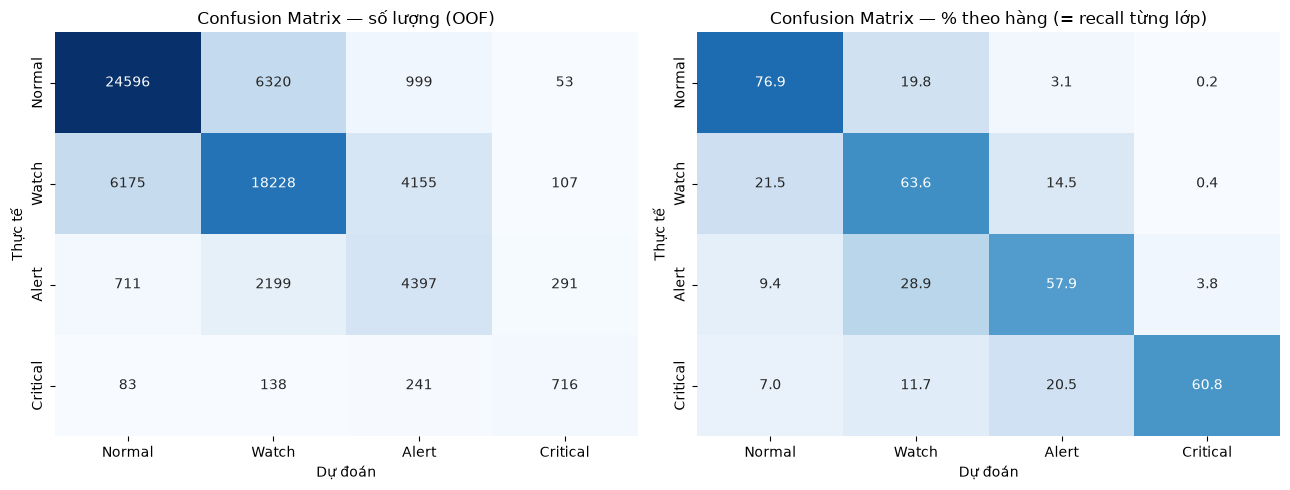

In [8]:
cm = confusion_matrix(y_dev, oof_pred, labels=[0, 1, 2, 3])
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=axes[0], cbar=False)
axes[0].set_title("Confusion Matrix — số lượng (OOF)")
axes[0].set_xlabel("Dự đoán"); axes[0].set_ylabel("Thực tế")

sns.heatmap(cm_norm, annot=True, fmt=".1f", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=axes[1], cbar=False, vmin=0, vmax=100)
axes[1].set_title("Confusion Matrix — % theo hàng (= recall từng lớp)")
axes[1].set_xlabel("Dự đoán"); axes[1].set_ylabel("Thực tế")

plt.tight_layout()
plt.savefig(f"{MODEL_DIR}/confusion_matrix.png", dpi=120)
plt.show()

## 6.7 Feature importance — bar chart
Trung bình importance qua 5 model (mỗi fold 1 model), vẽ bar chart ngang cho 15 feature quan trọng nhất — trực quan hơn bảng số khi cần nhìn nhanh feature nào đang chi phối quyết định của model.

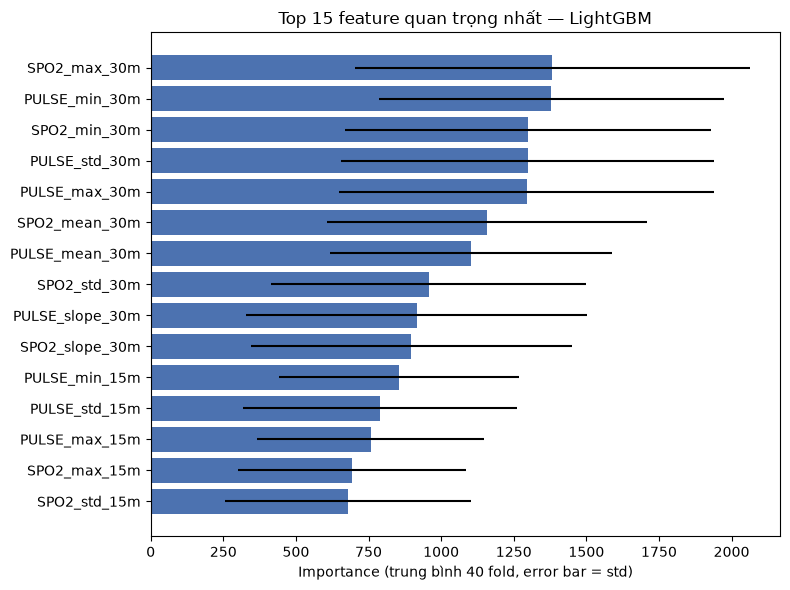

In [9]:
importances = []
for k in range(N_FOLDS):
    booster = lgb.Booster(model_file=f"{MODEL_DIR}/fold_{k}.txt")
    importances.append(booster.feature_importance())

importance_df = pd.DataFrame(np.array(importances).T, index=FEATURE_COLS,
                              columns=[f"fold_{k}" for k in range(N_FOLDS)])
importance_df["mean"] = importance_df.mean(axis=1)
importance_df["std"] = importance_df.iloc[:, :N_FOLDS].std(axis=1)

top15 = importance_df.sort_values("mean", ascending=False).head(15)

plt.figure(figsize=(8, 6))
plt.barh(top15.index[::-1], top15["mean"][::-1], xerr=top15["std"][::-1], color="#4c72b0")
plt.xlabel(f"Importance (trung bình {N_FOLDS} fold, error bar = std)")
plt.title("Top 15 feature quan trọng nhất — LightGBM")
plt.tight_layout()
plt.savefig(f"{MODEL_DIR}/feature_importance.png", dpi=120)
plt.show()

In [10]:
pd.set_option("display.max_rows", 50)
importance_df.sort_values("mean", ascending=False)[["mean", "std"]]

,mean,std
SPO2_max_30m,1383.300,680.284676
PULSE_min_30m,1379.775,594.890573
SPO2_min_30m,1299.750,630.194872
PULSE_std_30m,1297.600,642.042845
PULSE_max_30m,1295.500,645.613562
SPO2_mean_30m,1157.700,551.730202
PULSE_mean_30m,1103.700,485.058241
SPO2_std_30m,956.775,543.359941
PULSE_slope_30m,915.250,585.596420
SPO2_slope_30m,897.600,554.020957
